# Lab 03

In [1]:
import torch, math, time, json, random
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")
torch.manual_seed(1337); random.seed(1337); np.random.seed(1337)

Device: cuda Tesla T4


## 1. Load the data set(from Kaggle input)

Files found in /kaggle/input:
No Kaggle input found -> using Hugging Face (needs Internet = On)


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

... (5 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Loaded stories -> train: 30000 | val: 3000
--- Story 0 (701 chars) ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for shari 

--- Story 1 (705 chars) ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. B

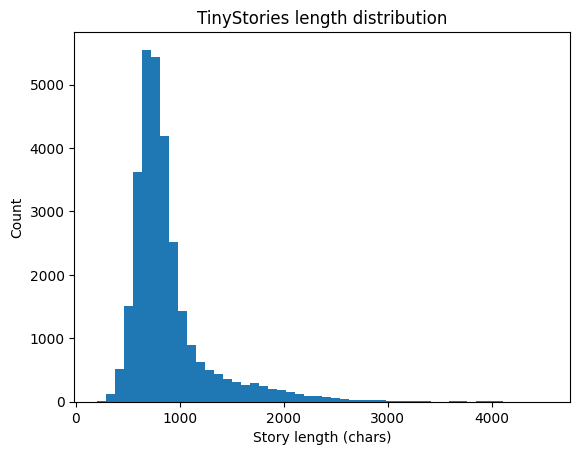

In [2]:
import glob, os
import pandas as pd

MAX_TRAIN, MAX_VAL = 30000, 3000

files = [p for p in glob.glob("/kaggle/input/**/*", recursive=True)
         if os.path.isfile(p) and p.lower().endswith((".txt", ".csv", ".parquet", ".json", ".jsonl"))]
print("Files found in /kaggle/input:")
for f in files: print("  ", f, f"({os.path.getsize(f)/1e6:.1f} MB)")

def read_stories(path, max_stories):
    ext = path.lower().rsplit(".", 1)[-1]
    if ext == "txt": 
        with open(path, encoding="utf-8", errors="ignore") as f:
            raw = f.read(max_stories * 1500)
        parts = raw.split("<|endoftext|>")[:-1]
        return [s.strip() for s in parts if s.strip()][:max_stories]
    if ext == "csv":      df = pd.read_csv(path, nrows=max_stories)
    elif ext == "parquet": df = pd.read_parquet(path).head(max_stories)
    else:                 df = pd.read_json(path, lines=(ext == "jsonl")).head(max_stories)
    col = "text" if "text" in df.columns else df.select_dtypes("object").columns[0]
    return df[col].astype(str).str.strip().tolist()

def pick(keys, exclude=()):
    for f in files:
        n = os.path.basename(f).lower()
        if any(k in n for k in keys) and not any(e in n for e in exclude): return f

if files:
    tr_file = pick(["train"], exclude=["valid", "val"]) or files[0]
    va_file = pick(["valid", "val"])
    train_all = read_stories(tr_file, MAX_TRAIN)
    if va_file: val_all = read_stories(va_file, MAX_VAL)
    else:       # no validation file: hold out the last 5% of train
        cut = int(len(train_all) * 0.95); train_all, val_all = train_all[:cut], train_all[cut:]
    print("Train file:", tr_file, "| Val file:", va_file)
else:
    print("No Kaggle input found -> using Hugging Face (needs Internet = On)")
    from datasets import load_dataset
    ds = load_dataset("roneneldan/TinyStories")
    train_all = ds["train"].select(range(MAX_TRAIN))["text"]
    val_all = ds["validation"].select(range(MAX_VAL))["text"]

print("Loaded stories -> train:", len(train_all), "| val:", len(val_all))
for i in range(3):
    print(f"--- Story {i} ({len(train_all[i])} chars) ---")
    print(train_all[i][:600], "\n")

lens = np.array([len(t) for t in train_all])
print(f"Chars per story: mean={lens.mean():.0f}, median={np.median(lens):.0f}, min={lens.min()}, max={lens.max()}")
print("Avg words per story:", np.mean([len(t.split()) for t in train_all]))
plt.hist(lens, bins=50); plt.xlabel("Story length (chars)"); plt.ylabel("Count"); plt.title("TinyStories length distribution"); plt.show()

## 2. Preprocess: subset + character-level tokenization

In [3]:
N_TRAIN, N_VAL = min(20000, len(train_all)), min(2000, len(val_all))   # raise MAX_TRAIN above + N_TRAIN for better stories
train_texts = train_all[:N_TRAIN]
val_texts   = val_all[:N_VAL]

# Keep the vocabulary small: restrict to characters seen in the training subset
train_text = "\n".join(t.strip() for t in train_texts) + "\n"
val_text   = "\n".join(t.strip() for t in val_texts) + "\n"
chars = sorted(set(train_text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
vocab_size = len(chars)
unk = stoi[" "]
encode = lambda s: [stoi.get(c, unk) for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data   = torch.tensor(encode(val_text), dtype=torch.long)
print("Vocab size:", vocab_size)
print("Train tokens:", len(train_data), "| Val tokens:", len(val_data))
print(decode(encode("Once upon a time")))

Vocab size: 97
Train tokens: 17910906 | Val tokens: 1593942
Once upon a time


## 3. Prepare training data


In [4]:
block_size = 256
batch_size = 64

def get_batch(split):
    data = train_data if split == "train" else val_data
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)

x, y = get_batch("train")
print("x:", x.shape, "y:", y.shape)
print("x[0][:30] ->", repr(decode(x[0][:30].tolist())))
print("y[0][:30] ->", repr(decode(y[0][:30].tolist())))

x: torch.Size([64, 256]) y: torch.Size([64, 256])
x[0][:30] -> ' toast. She was very proud of '
y[0][:30] -> 'toast. She was very proud of h'


## 4. Transformer architecture

In [5]:
import torch, math, time, json, random
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = self.attn_drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y))

class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(),
                                 nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))
    def forward(self, x): return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = MultiHeadSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward(n_embd, dropout)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # residual connection + pre-LayerNorm
        x = x + self.ffn(self.ln2(x))    # residual connection
        return x

class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size, n_layer, n_head, n_embd, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight   # weight tying
        self.apply(self._init)

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        x = self.ln_f(self.blocks(x))
        logits = self.head(x)
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=40):
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.block_size:])
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            nxt = torch.multinomial(F.softmax(logits, dim=-1), 1)
            idx = torch.cat([idx, nxt], dim=1)
        return idx

## 5. Initialize model, loss and optimizer

In [6]:
config = dict(vocab_size=vocab_size, block_size=block_size, n_layer=4, n_head=4, n_embd=256, dropout=0.1)
model = TinyTransformer(**config).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")
# Loss = cross-entropy (inside forward). Optimizer = AdamW with cosine LR decay (set up in train()).

Parameters: 3.25M


## 6-8. Train, monitor, evaluate

In [7]:
@torch.no_grad()
def evaluate(model, iters=40):
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(iters):
            x, y = get_batch(split)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                _, loss = model(x, y)
            losses.append(loss.item())
        out[split] = float(np.mean(losses))
    return out

def train(model, epochs=15, steps_per_epoch=300, lr=3e-4, verbose=True):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1, betas=(0.9, 0.95))
    total = epochs * steps_per_epoch
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total, pct_start=0.05, anneal_strategy="cos")
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
    hist = {"train": [], "val": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        run = 0.0
        for _ in range(steps_per_epoch):
            x, y = get_batch("train")
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                _, loss = model(x, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()          # backpropagation
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()   # parameter update
            run += loss.item()
        ev = evaluate(model)
        hist["train"].append(run / steps_per_epoch); hist["val"].append(ev["val"])
        if verbose:
            print(f"Epoch {ep:2d}/{epochs} | train {hist['train'][-1]:.4f} | val {ev['val']:.4f} | "
                  f"val PPL {math.exp(ev['val']):.2f} | {time.time()-t0:.0f}s")
    return hist

history = train(model, epochs=15, steps_per_epoch=300)

/tmp/ipykernel_50/1628577099.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))


Epoch  1/15 | train 2.7031 | val 2.1933 | val PPL 8.96 | 23s
Epoch  2/15 | train 2.0006 | val 1.6350 | val PPL 5.13 | 46s
Epoch  3/15 | train 1.6064 | val 1.3517 | val PPL 3.86 | 70s
Epoch  4/15 | train 1.3889 | val 1.1898 | val PPL 3.29 | 96s
Epoch  5/15 | train 1.2576 | val 1.1135 | val PPL 3.05 | 122s
Epoch  6/15 | train 1.1756 | val 1.0460 | val PPL 2.85 | 148s
Epoch  7/15 | train 1.1138 | val 1.0082 | val PPL 2.74 | 173s
Epoch  8/15 | train 1.0739 | val 0.9765 | val PPL 2.66 | 199s
Epoch  9/15 | train 1.0404 | val 0.9530 | val PPL 2.59 | 225s
Epoch 10/15 | train 1.0173 | val 0.9351 | val PPL 2.55 | 251s
Epoch 11/15 | train 0.9992 | val 0.9222 | val PPL 2.51 | 277s
Epoch 12/15 | train 0.9859 | val 0.9116 | val PPL 2.49 | 303s
Epoch 13/15 | train 0.9783 | val 0.9042 | val PPL 2.47 | 329s
Epoch 14/15 | train 0.9717 | val 0.9016 | val PPL 2.46 | 355s
Epoch 15/15 | train 0.9706 | val 0.8979 | val PPL 2.45 | 382s


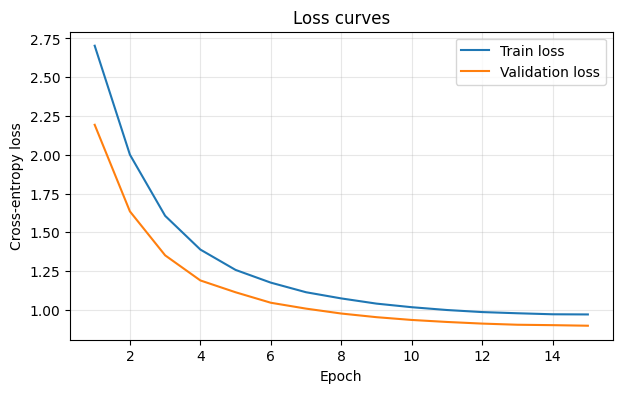

Final validation loss: 0.8979
Validation perplexity: 2.45  (random guess would be ~97)


In [8]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history["train"]) + 1), history["train"], label="Train loss")
plt.plot(range(1, len(history["val"]) + 1), history["val"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.legend(); plt.grid(alpha=.3); plt.title("Loss curves"); plt.show()

final_val = history["val"][-1]
print(f"Final validation loss: {final_val:.4f}")
print(f"Validation perplexity: {math.exp(final_val):.2f}  (random guess would be ~{vocab_size})")

**Observation:** Training and validation loss both decreased steadily over 15 epochs. Validation loss dropped from 2.1933 (perplexity 8.96) in epoch 1 to 0.8979 (perplexity 2.45) in epoch 15, far better than the random-guess perplexity of ~97. Validation loss stayed below training loss throughout without diverging upward, showing good generalization with no signs of overfitting. The rate of improvement slows in later epochs, meaning more epochs would yield only small, diminishing gains.

## 9. Generate stories

In [9]:
def generate_text(model, prompt="Once upon a time", max_new_tokens=500, temperature=0.8, top_k=40):
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens, temperature, top_k)
    return decode(out[0].tolist())

for t in [0.5, 0.8, 1.1]:
    print(f"===== temperature {t} =====")
    print(generate_text(model, "Once upon a time", 400, temperature=t), "\n")

===== temperature 0.5 =====
Once upon a time, there was a little girl named Lily. She loved to play with her toys and saw a big bear. One day, Lily went to the park with her friends. She was so happy and liked to play with her friends.

One day, Lily went to the park with her mommy and daddy. She saw a lot. She looked at her toys and said, "Thank you, Lily. You are a good friend. You are very scared. You are sorry. You are a good friend. Yo 

===== temperature 0.8 =====
Once upon a time, there was a little bird who was one. The dragon smiled and said, "I did it was so worried. The bear looked at the tree and Spot was a group in the river. They decided to go to the park, but the rainbow that are not happy. They wished they saw the pigeople with his walk. The clock was very nice and knew his mom. He was so excited.

The owl of the mouse and said, "Thank you, mommy. I am a very wal 

===== temperature 1.1 =====
Once upon a time, there was a little girl named Lily who faully block into her

**Observation:** The model learned the simple story style and common phrases like *"Once upon a time, there was a little girl named Lily."* Lower temperature (`0.5`) gives cleaner, safer text with some repetition, while higher temperatures (`0.8` and `1.1`) give more variety along with spelling and grammar mistakes (like *"pigeople"* and *"dreasure"*). The stories are not fully coherent because the model is small and generates text character by character.

## 10. Experiment with model settings


### 1 layer, 2 heads


/tmp/ipykernel_50/1628577099.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))


params=0.88M | val loss=1.3748 | PPL=3.95
Once upon a timess and the said. What so her the down to out and said, "Wow, Momb and dog to do. It was smile.

They sso her day want they were cocked to the firhen beautiful didn't go like and to played to the bull of the wasnd the park.

Mom said, "We the boy fave

### 2 layers, 4 heads
params=1.67M | val loss=1.2599 | PPL=3.53
Once upon a time, there was a little girl named Lila. She felt something langed who walking and to go on the delirt.

Solly, helpopped and said, "I won't go friends the park."

Anna with the knew he lived home, but would reade the word for him and sled they her snow

### 4 layers, 4 heads
params=3.25M | val loss=1.1827 | PPL=3.26
Once upon a time, there was a little girl named Youseday tel in the spock a picken."

As Ben for her curpled and said, "Tom, and Jen. It was old the park in the wing in the colors about in the couldn't the ball't." Lily felt sad. Ally was so happy her was a quick. S

### 6 layers, 8 heads
para

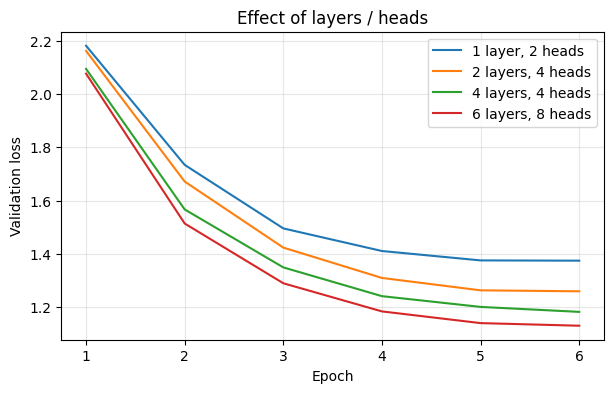

In [10]:
experiments = {
    "1 layer, 2 heads":   dict(n_layer=1, n_head=2, n_embd=256),
    "2 layers, 4 heads":  dict(n_layer=2, n_head=4, n_embd=256),
    "4 layers, 4 heads":  dict(n_layer=4, n_head=4, n_embd=256),
    "6 layers, 8 heads":  dict(n_layer=6, n_head=8, n_embd=256),
}
EXP_EPOCHS = 6
results, samples = {}, {}
for name, cfg in experiments.items():
    print(f"\n### {name}")
    c = dict(config); c.update(cfg)
    m = TinyTransformer(**c).to(device)
    h = train(m, epochs=EXP_EPOCHS, steps_per_epoch=300, verbose=False)
    results[name] = h
    samples[name] = generate_text(m, "Once upon a time", 250)
    print(f"params={sum(p.numel() for p in m.parameters())/1e6:.2f}M | val loss={h['val'][-1]:.4f} | PPL={math.exp(h['val'][-1]):.2f}")
    print(samples[name])

plt.figure(figsize=(7, 4))
for name, h in results.items(): plt.plot(range(1, EXP_EPOCHS + 1), h["val"], label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.legend(); plt.grid(alpha=.3); plt.title("Effect of layers / heads"); plt.show()

**Observation:** Larger models with more layers and attention heads achieved lower validation loss and perplexity across all 6 epochs. Validation loss improved from 1.3748 (PPL 3.95, 1 layer, 2 heads) to 1.1308 (PPL 3.10, 6 layers, 8 heads). The 1-layer model produced many broken words and fragments, while deeper models generated more readable sentences, though they require more parameters (0.88M up to 4.83M) and longer training time.

In [11]:
# Effect of the number of epochs: same architecture, different training length
epoch_results = {}
for ep in [3, 8, 15]:
    m = TinyTransformer(**config).to(device)
    h = train(m, epochs=ep, steps_per_epoch=300, verbose=False)
    epoch_results[ep] = h["val"][-1]
    print(f"epochs={ep:2d} | val loss={h['val'][-1]:.4f} | PPL={math.exp(h['val'][-1]):.2f}")
    print(generate_text(m, "Once upon a time", 200), "\n")

/tmp/ipykernel_50/1628577099.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))


epochs= 3 | val loss=1.5770 | PPL=4.84
Once upon a time, he bleed carould a tagid, "Once upon a time, was a she momaze. It's love pice on she mad some coul suck it it shis make. He and and wery some hom her friend. He is of a they to wloy. His a liked man 

epochs= 8 | val loss=1.0808 | PPL=2.95
Once upon a time, there was a little girl named She loved to explore. She looked around and her dad asked him the fast when she would so had something from of when he was very sad. One day, she was very very happy to 

epochs=15 | val loss=0.8901 | PPL=2.44
Once upon a time there was a little girl named Lily. She loved to play out of her mommy came outside and was very sad. One day, Lily's mom saw a great dog outside with a water. Lily was always happy and said that it' 



**Observation:** More training epochs reduced loss: 1.577 (perplexity 4.84) after 3 epochs, 1.080 (2.95) after 8 epochs and 0.890 (2.43) after 15 epochs. With only 3 epochs the text was mostly broken words, and after 8 and 15 epochs it contained real words and simple sentences. Gains get smaller after about 8 epochs.

## 11. Save the model + config

In [12]:
import os
os.makedirs("/kaggle/working", exist_ok=True)
torch.save({"model_state": model.state_dict(), "config": config, "chars": chars}, "/kaggle/working/tiny_transformer.pt")
json.dump(config, open("/kaggle/working/config.json", "w"), indent=2)
print("Saved to /kaggle/working/ (download from the Output tab)")

# Reload test
ckpt = torch.load("/kaggle/working/tiny_transformer.pt", map_location=device)
m2 = TinyTransformer(**ckpt["config"]).to(device)
m2.load_state_dict(ckpt["model_state"])
print(generate_text(m2, "One day, a little girl", 200))

Saved to /kaggle/working/ (download from the Output tab)
One day, a little girl named Lily. She loved her parents playing with her dad. One day, Lily went to the park and started to play away. Lily put the ball and ran to the sun and took a paper. Lily was so happy to listen to 


## Optional: Gradio chat window

In [13]:
try:
    import gradio as gr
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'])
    import gradio as gr

def chat(prompt, max_new_tokens, temperature, top_k):
    return generate_text(m2, prompt, int(max_new_tokens), temperature, int(top_k))

demo = gr.Interface(
    fn=chat,
    inputs=[gr.Textbox(value="Once upon a time", label="Story prompt"),
            gr.Slider(50, 800, value=300, step=10, label="Max new characters"),
            gr.Slider(0.2, 1.5, value=0.8, step=0.05, label="Temperature"),
            gr.Slider(5, 60, value=40, step=1, label="Top-k")],
    outputs=gr.Textbox(label="Generated story", lines=15),
    title="Tiny Transformer Story Generator")
demo.launch(share=True)   # share=True gives a public link usable from Kaggle

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://fb440ece0815945519.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Discussion: mechanisms that improve performance
- **Self-attention** lets every token look at all earlier tokens, capturing long-range context; **multiple heads** learn different relationships in parallel.
- **Causal masking** prevents peeking at future tokens, so training matches generation.
- **Positional embeddings** give the model word-order information.
- **Residual connections** keep gradients flowing through deep stacks; **LayerNorm** stabilises activations and training.
- **Feed-forward layers + GELU** add non-linear capacity per token.
- **Dropout and weight decay** reduce overfitting; **weight tying** cuts parameters.
- **AdamW, LR warm-up + cosine decay, gradient clipping** give stable, fast optimisation.
- **Mixed precision (fp16)** speeds up GPU training; **temperature and top-k sampling** improve text quality at generation time.